# 投资组合风险 Monte Carlo

本实验利用真实股票收益估计平均收益、波动和股票之间的相关性，再生成收益情景，比较组合的单日尾部损失。

股票池为招商银行、长江电力、万科 A、格力电器和比亚迪。我们比较等权与市值加权两种组合，各方法使用相同的数据和组合权重。

本 Notebook 使用已保存的历史数据，不在运行时联网下载。网页展示预先执行的代码与结果。


[返回理论正文](../../lectures/monte-carlo.qmd#sec-mc-portfolio) · [下载 Notebook (ZIP)](../../resources/monte-carlo/downloads/03-portfolio-risk-monte-carlo.zip)

页面展示交接包已保存的执行结果；渲染不执行代码。

本地复现使用 `python tools/monte-carlo/run_portfolio.py`，运行器组装旧代码所需冻结依赖，不联网取数。原始供应商缓存仅本地保留。

In [1]:
# 从任务根目录或 notebooks 目录启动均可，ZIP 解压后路径仍有效。
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
if not (ROOT / "code/analysis.py").exists():
    ROOT = ROOT.parent
assert (ROOT / "code/analysis.py").exists(), "请在解压目录或 notebooks 目录启动"
sys.path.insert(0, str(ROOT / "code"))
import analysis as a
pd.set_option("display.max_columns", 16)
pd.set_option("display.width", 150)
print("固定随机种子：", a.SEED, "；主分析 B：", a.B)

固定随机种子： 20261001 ；主分析 B： 100000


## 1. 数据来源与样本区间

个股价格通过 AKShare 获取，日收益率由后复权收盘价计算。市值权重使用 2026-09-30 的总市值数据。

五只股票都有有效日收益率的样本区间为 2016-09-05 至 2026-09-30，共 2397 日。下载接口、日期和版本记录保留在本地复现资料中。


In [2]:
# 展示真实接口探测记录，而非重新发送请求。
probes = json.loads((ROOT / "logs/api-probes.json").read_text(encoding="utf-8"))
display(pd.DataFrame([{k:v for k,v in p.items() if k in ["interface","status","rows","retrieved_date","akshare_version"]} for p in probes]))

,interface,retrieved_date,akshare_version,status,rows
0,stock_zh_a_hist,2026-10-01,1.18.39,FAILED,NaN
1,stock_value_em,2026-10-01,1.18.39,OK,2123.0
2,stock_zh_valuation_baidu,2026-10-01,1.18.39,OK,607.0
3,stock_zh_a_hist_tx,2026-10-01,1.18.39,OK,21.0


## 2. 日收益率与共同交易日

个股的简单日收益率定义为 $R_{it}=P^{adj}_{it}/P^{adj}_{i,t-1}-1$，其中 $P^{adj}$ 为后复权收盘价。

先按交易日期计算各只股票的日收益率，再保留五只股票都有有效收益的日期。不填充停牌或缺报数据，避免将跨多日的价格变化误作单日收益。下表检查本例五只股票的数据覆盖和缺失区间。


In [3]:
# QA 函数保存每只股票的日期覆盖、缺口、调整差异和被排除日期。
returns, weights, qa = a.qa_data()
display(qa.loc[qa['code'].astype(str).isin(a.FINAL)])
missing = pd.read_csv(a.OUT / "missing_intervals.csv", dtype={"code": str})
display(missing.loc[missing["code"].isin(a.FINAL)])
print("最终共同单日收益：", returns.index.min().date(), "至", returns.index.max().date(), "；n =", len(returns))
assert returns.notna().all().all() and np.isfinite(returns.to_numpy()).all()

,code,name,first_date,last_date,n_valid,market_dates,missing_rate,max_missing_market_days,nonpositive_hfq,zero_volume,valid_daily_returns,max_abs_return,flagged_days
1,600900,长江电力,2016-01-04,2026-09-30,2594,2611,0.006511,10,0,0,2591,0.046347,413
2,000002,万科 A,2016-07-04,2026-09-30,2485,2611,0.048257,121,0,0,2481,0.093215,600
3,000651,格力电器,2016-01-04,2026-09-30,2454,2611,0.060130,135,0,0,2448,0.088345,876
4,002594,比亚迪,2016-01-04,2026-09-30,2611,2611,0.000000,0,0,0,2611,0.099651,90
5,600036,招商银行,2016-01-04,2026-09-30,2611,2611,0.000000,0,0,0,2611,0.089782,751


,code,start,end,missing_market_days
0,600900,2016-03-03,2016-03-10,6
1,600900,2021-11-29,2021-12-10,10
2,600900,2022-10-26,2022-10-26,1
3,000002,2016-01-04,2016-07-01,121
4,000002,2017-01-12,2017-01-12,1
5,000002,2017-06-07,2017-06-09,3
6,000002,2017-07-17,2017-07-17,1
7,000651,2016-02-22,2016-09-01,135
8,000651,2016-10-31,2016-11-16,13
9,000651,2016-11-29,2016-11-30,2


最终共同单日收益： 2016-09-05 至 2026-09-30 ；n = 2397


## 3. 两种组合权重

等权组合中每只股票的权重均为 20%。市值加权组合采用 $w_{i}=M_{i}/\sum_{j=1}^{5}M_{j}$，其中 $M_{i}$ 为第 $i$ 只股票在 2026-09-30 的总市值。

比较不同模拟方法时，组合权重保持不变。下面列出五只股票的两组权重。


In [4]:
display(weights)
W = weights[["equal_weight", "value_weight"]].to_numpy()
assert np.allclose(W.sum(axis=0), 1)
assert weights.value_weight.max() <= 0.40
print("市值加权最大权重：", f"{weights.value_weight.max():.4%}")

,code,name,sector,equal_weight,value_weight,total_market_cap_yuan,reference_date
0,600036,招商银行,银行,0.2,0.376514,1.040571e+12,2026-09-30
1,600900,长江电力,电力,0.2,0.252677,6.983229e+11,2026-09-30
2,000002,万科 A,房地产,0.2,0.018390,5.082482e+10,2026-09-30
3,000651,格力电器,家电,0.2,0.077585,2.144218e+11,2026-09-30
4,002594,比亚迪,汽车,0.2,0.274833,7.595537e+11,2026-09-30


市值加权最大权重： 37.6514%


## 4. 历史分布与联合正态模拟

$\hat{\mu}$ 是五维日均收益向量，$\hat{\Sigma}$ 是采用 $n-1$ 分母的五乘五样本协方差矩阵。模型为 $\mathbf R^{*}\sim N_5(\hat{\mu},\hat{\Sigma})$；每一行模拟一个共同交易日情景，组合收益为 $R_p^{*}=\mathbf w^{\top}\mathbf R^{*}$。

固定权重乘以每日日收益意味着恒定目标权重的单日期间组合，跨期解释隐含每日恢复目标权重及忽略交易成本；它不等于买入后不调整股数。此处只研究单日无条件风险，不模拟一条真实未来路径。

In [5]:
# 直接展示核心联合抽样，不能逐只股票独立模拟。
mu_hat = returns.mean().to_numpy()
Sigma_hat = returns.cov().to_numpy()
rng_param = np.random.default_rng(a.SEED)
sim_returns = rng_param.multivariate_normal(mu_hat, Sigma_hat, size=a.B)
portfolio_hist = returns.to_numpy() @ W
portfolio_param = sim_returns @ W
display(returns.corr())
print("协方差最小特征值：", np.linalg.eigvalsh(Sigma_hat).min())

,600036,600900,000002,000651,002594
600036,1.000000,0.302844,0.495218,0.425616,0.205295
600900,0.302844,1.000000,0.186231,0.210382,0.063632
000002,0.495218,0.186231,1.000000,0.422997,0.197993
000651,0.425616,0.210382,0.422997,1.000000,0.249047
002594,0.205295,0.063632,0.197993,0.249047,1.000000


协方差最小特征值： 5.829804595267422e-05


## 5. Historical bootstrap

每次抽取真实矩阵的一整行，保留同一天五只股票的共同波动。这里得到经验单日收益分布的再抽样，不是估计均值标准误的 bootstrap 分布，也不会创造历史中未见过的灾难事件。按行独立重抽不保留跨日序列相关或波动聚集。

In [6]:
rng_boot = np.random.default_rng(a.SEED + 1)
idx = rng_boot.integers(0, len(returns), size=a.B)
boot_returns = returns.to_numpy()[idx, :]
portfolio_boot = boot_returns @ W
# 辅助函数使用同一输入和种子，保存结果表、解析校验与多 B / 多种子检查。
arrays = a.simulate(returns, weights)
assert np.array_equal(arrays["Parametric MC"], portfolio_param)
assert np.array_equal(arrays["Bootstrap"], portfolio_boot)
display(pd.read_csv(a.OUT / "summary_statistics.csv"))

,asset,method,mean_daily,vol_daily,skew,kurtosis_excess,q01,q05,minimum,n
0,600036,Historical,0.000490,0.014656,0.370282,3.026958,-0.035750,-0.021581,-0.074713,2397
1,600900,Historical,0.000388,0.008192,0.269493,2.539084,-0.020293,-0.012338,-0.046347,2397
2,000002,Historical,-0.000271,0.016575,0.718153,4.654846,-0.040915,-0.024221,-0.079444,2397
3,000651,Historical,0.000397,0.014529,0.414038,4.949396,-0.038121,-0.020994,-0.085197,2397
4,002594,Historical,0.000921,0.025112,0.455224,2.586995,-0.065162,-0.036273,-0.099509,2397
5,Equal-weight,Historical,0.000385,0.010433,-0.080790,2.590953,-0.029707,-0.015930,-0.056575,2397
6,Value-weight,Historical,0.000561,0.011013,0.029060,2.279853,-0.029958,-0.016656,-0.050451,2397
7,Equal-weight,Parametric MC,0.000393,0.010464,0.008274,0.037837,-0.023962,-0.016806,-0.051085,100000
8,Value-weight,Parametric MC,0.000562,0.011041,0.010887,0.035220,-0.025235,-0.017513,-0.053598,100000
9,Equal-weight,Bootstrap,0.000412,0.010506,-0.108787,2.558969,-0.030191,-0.015967,-0.056575,100000


## 6. 分布与尾部损失

令损失 $L=-R_p$。95% VaR 为损失的 95% 分位数，通常以正损失比例报告；数值表以小数存储，乘 100 后为百分比。95% ES 为最坏 5% 概率质量的平均损失。经验分布有重复值时，对边界观测按尾部概率质量分数计权，避免把所有相同分位点观测纳入而超过 5%。

95% VaR 与 ES 衡量不同位置，不能因其中一个较小便断言整个尾部被低估。辅助表同时保留 99% 指标。所有指标均为单日，不作年化。

In [7]:
risk_table = pd.read_csv(a.OUT / "risk_metrics.csv")
display(risk_table)
# 用解析正态结果检查 MC 计算，不能把解析结果冒充模拟输出。
display(pd.read_csv(a.OUT / "normal_analytic_reference.csv"))
display(pd.read_csv(a.OUT / "B_stability.csv").groupby(["B","portfolio","method"])[["VaR_95","ES_95"]].agg(["mean","min","max"]))

,portfolio,method,VaR_95,ES_95,VaR_99,ES_99
0,Equal-weight,Historical,0.015930,0.023925,0.029707,0.037311
1,Value-weight,Historical,0.016656,0.024809,0.029958,0.037296
2,Equal-weight,Parametric MC,0.016806,0.021200,0.023962,0.027593
3,Value-weight,Parametric MC,0.017513,0.022162,0.025235,0.028987
4,Equal-weight,Bootstrap,0.015967,0.024207,0.030191,0.037824
5,Value-weight,Bootstrap,0.016714,0.025101,0.030053,0.037766


,portfolio,mean_daily,vol_daily,VaR_95,ES_95
0,Equal-weight,0.000385,0.010433,0.016775,0.021135
1,Value-weight,0.000561,0.011013,0.017553,0.022155


VaR_95                         ES_95                    
                                       mean       min       max      mean       min       max
B      portfolio    method                                                                   
10000  Equal-weight Bootstrap      0.015635  0.015460  0.015928  0.023429  0.022649  0.023962
                    Parametric MC  0.016684  0.016466  0.016799  0.020933  0.020692  0.021079
       Value-weight Bootstrap      0.016210  0.015621  0.016581  0.024265  0.023511  0.024707
                    Parametric MC  0.017556  0.017245  0.017775  0.021979  0.021624  0.022205
50000  Equal-weight Bootstrap      0.015925  0.015828  0.016020  0.023878  0.023835  0.023919
                    Parametric MC  0.016666  0.016544  0.016801  0.021000  0.020946  0.021069
       Value-weight Bootstrap      0.016703  0.016581  0.016815  0.024761  0.024648  0.024889
                    Parametric MC  0.017521  0.017416  0.017597  0.022081  0.022032  0.022127
100000 Equal-weight Bootstrap      0.015957  0.015939  0.015967  0.023865  0.023841  0.023884
                    Parametric MC  0.016760  0.016690  0.016898  0.021091  0.021035  0.021127
       Value-weight Bootstrap      0.016706  0.016642  0.016763  0.024765  0.024755  0.024785
                    Parametric MC  0.017541  0.017521  0.017579  0.022131  0.022109  0.022172
500000 Equal-weight Bootstrap      0.015948  0.015939  0.015967  0.023919  0.023912  0.023925
                    Parametric MC  0.016752  0.016717  0.016774  0.021086  0.021050  0.021105
       Value-weight Bootstrap      0.016730  0.016714  0.016763  0.024840  0.024819  0.024865
                    Parametric MC  0.017547  0.017532  0.017568  0.022109  0.022098  0.022129

## 7. 图形核对

价格图用于识别相对走势，相关矩阵用于观察共同波动，单股分布与组合分布图用于检查形状。组合图保留完整分布，并单独放大最差 10% 的经验分布函数。稳定性图中的阴影为三个随机种子结果的范围，不是统计置信区间。

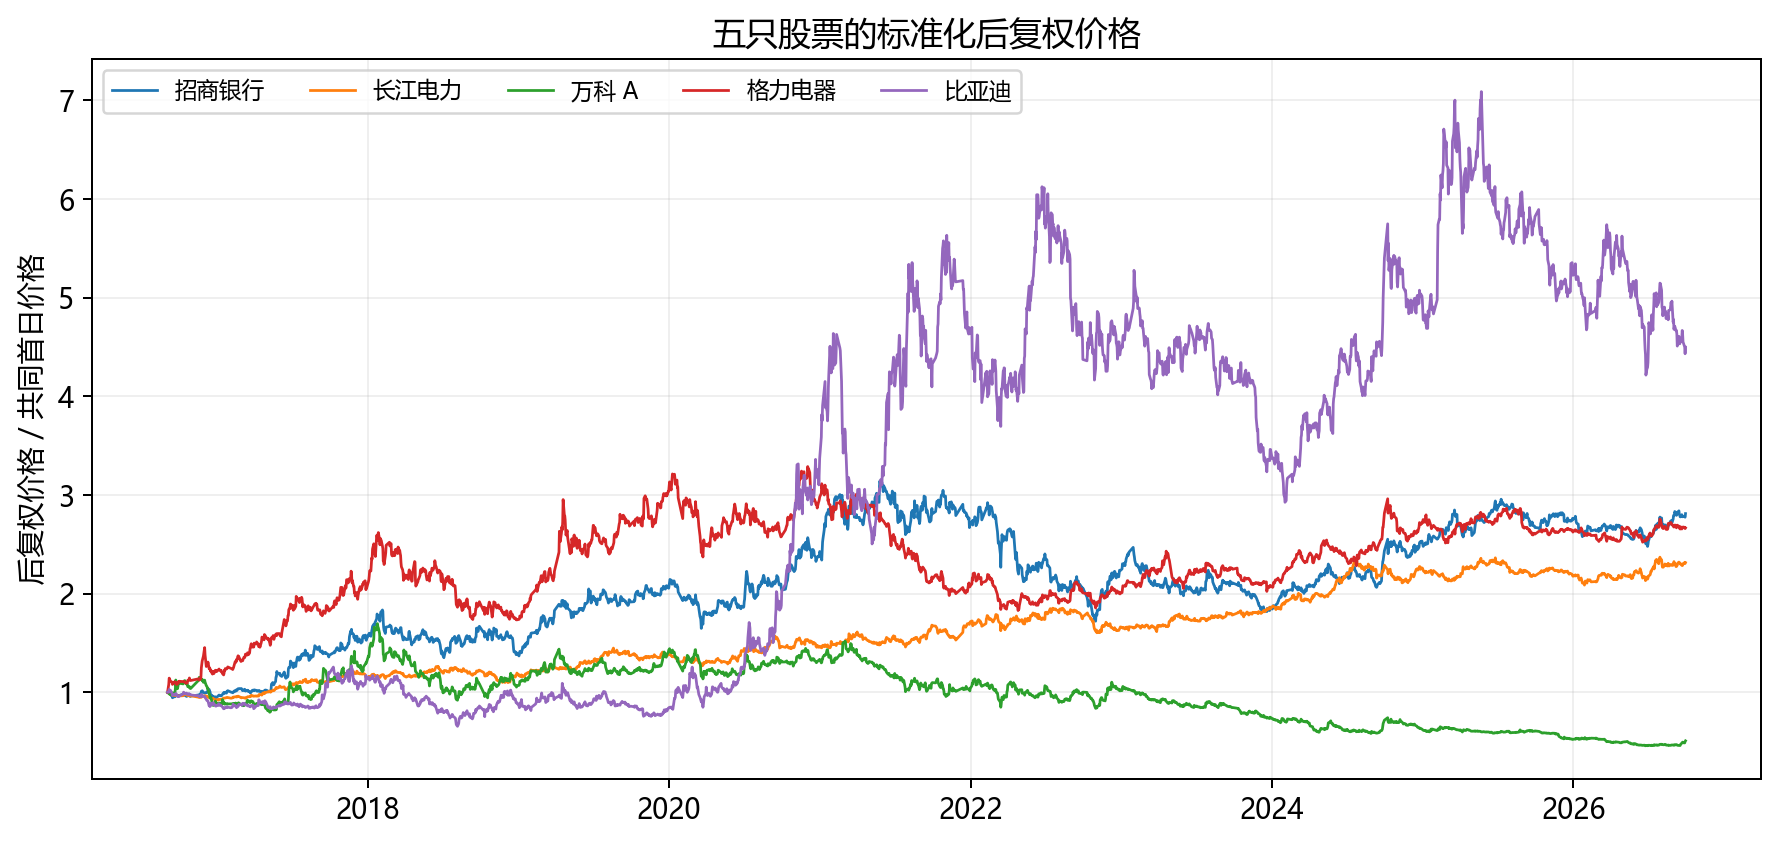

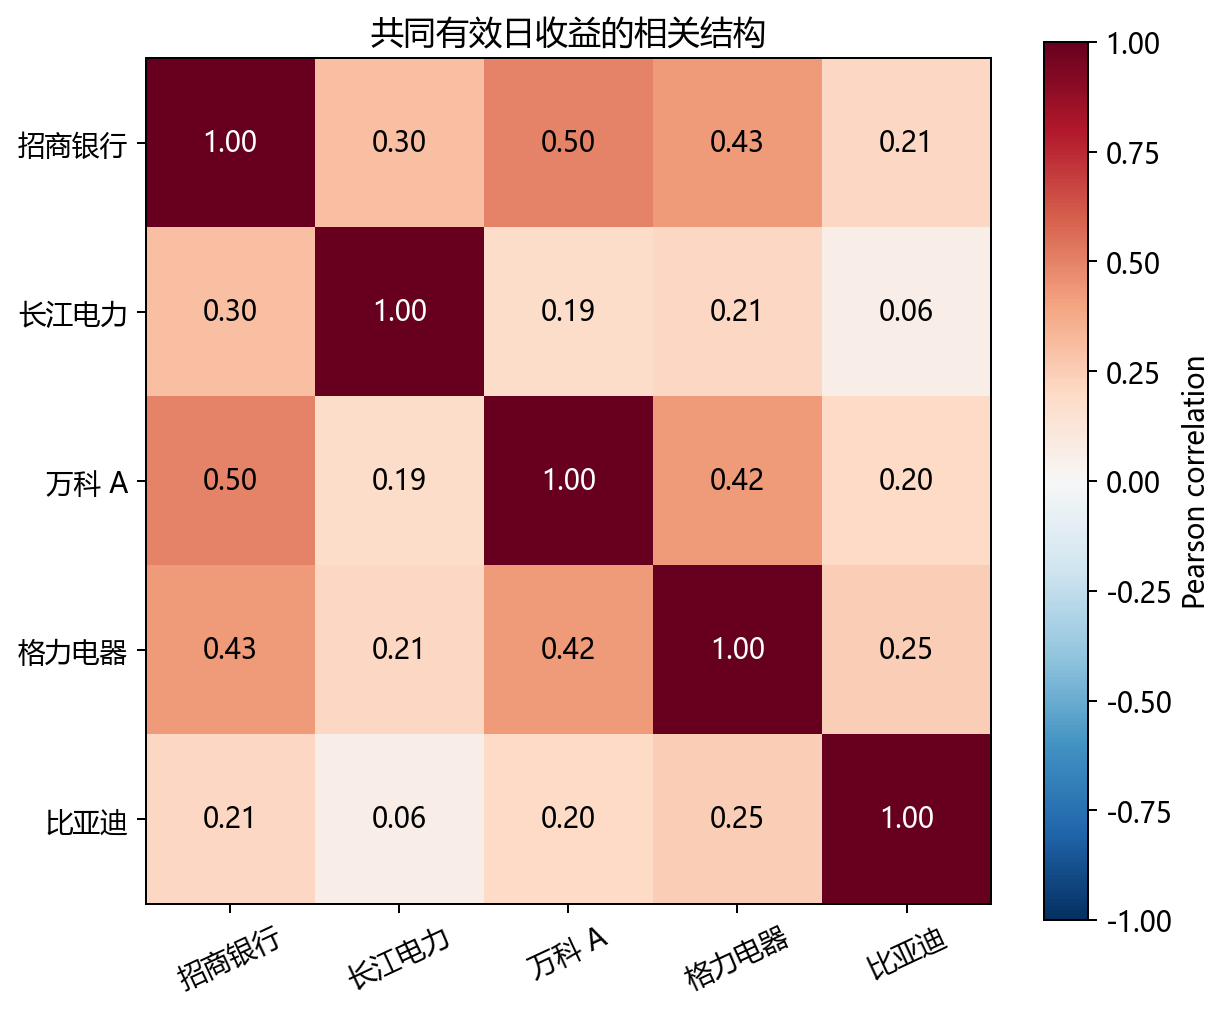

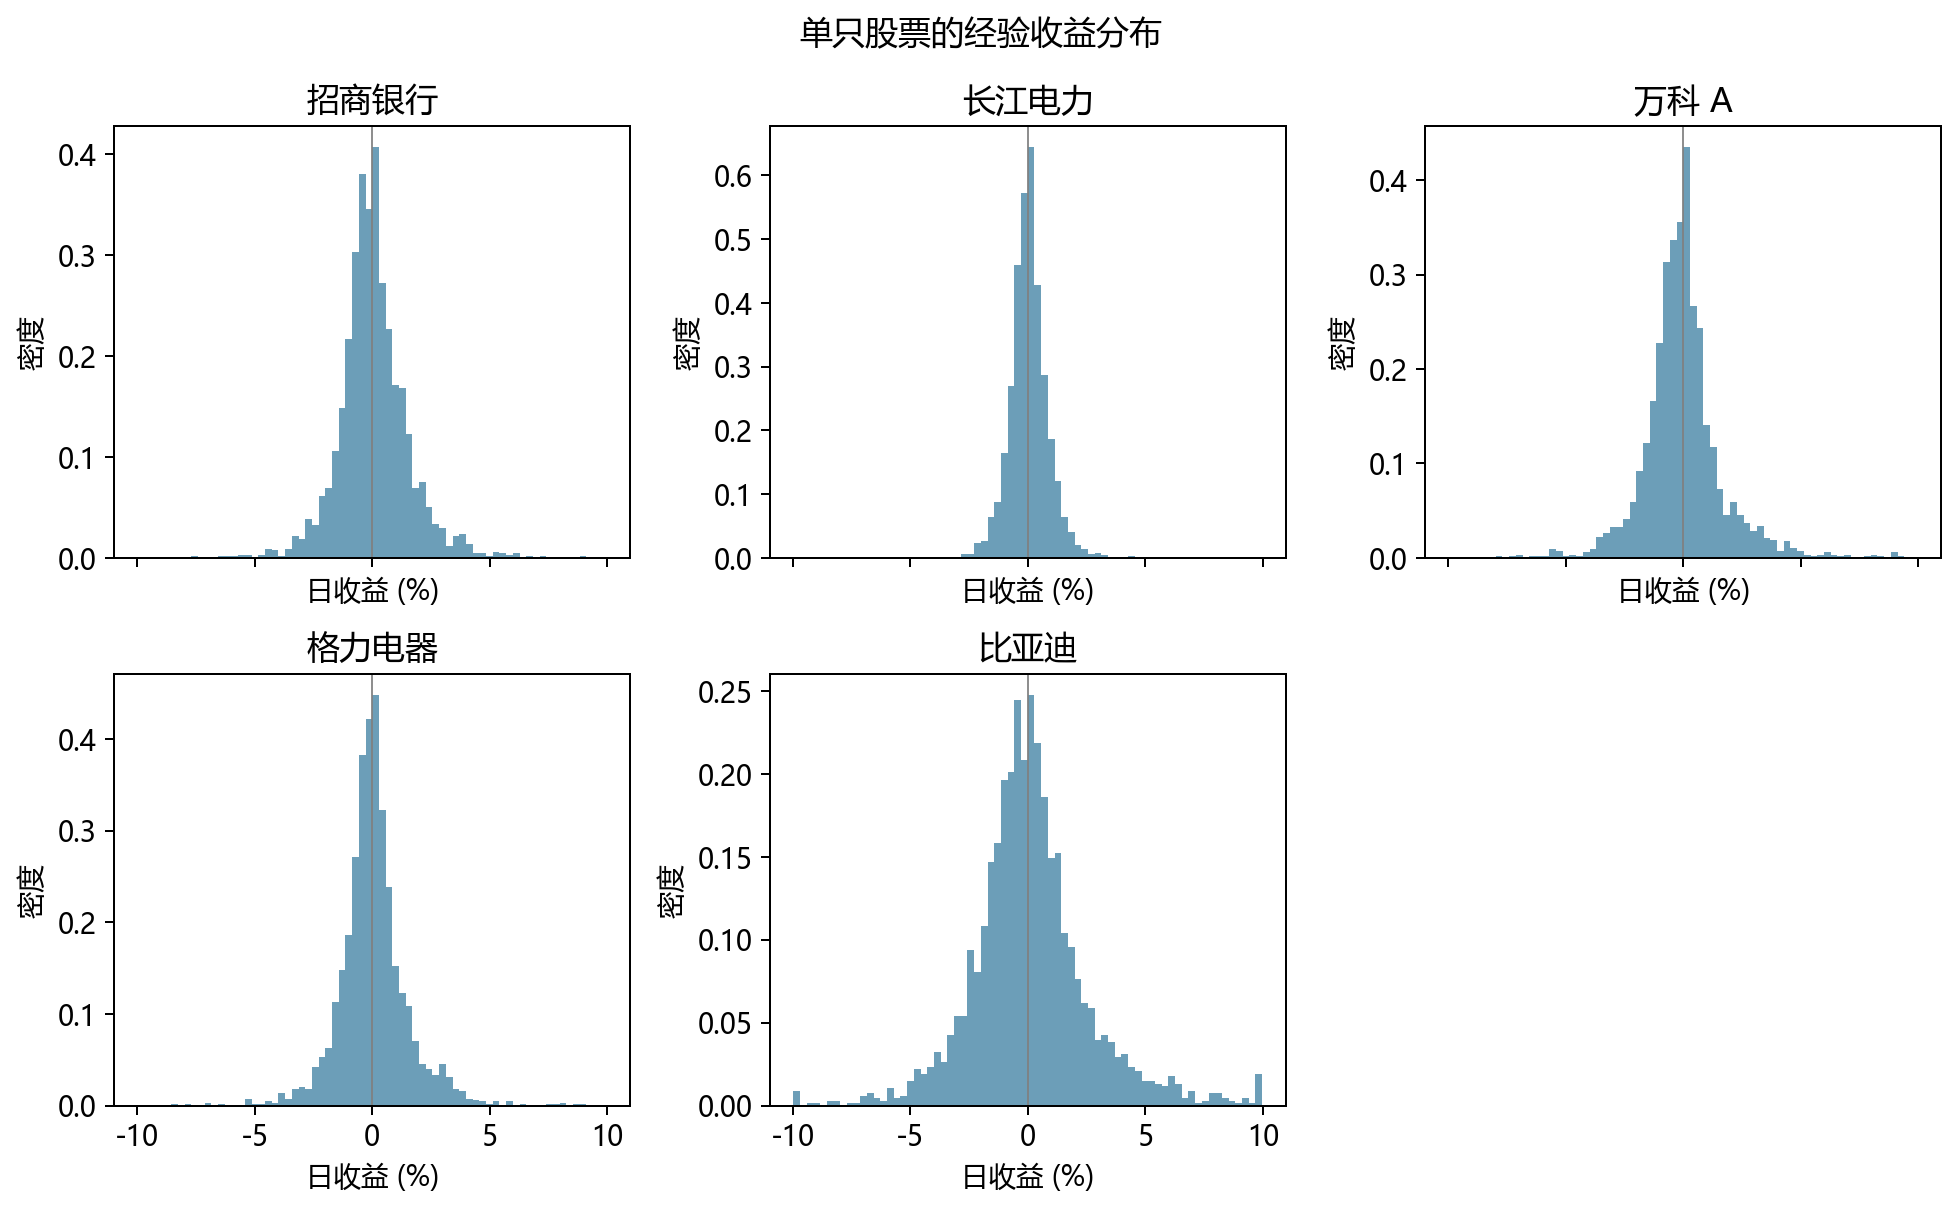

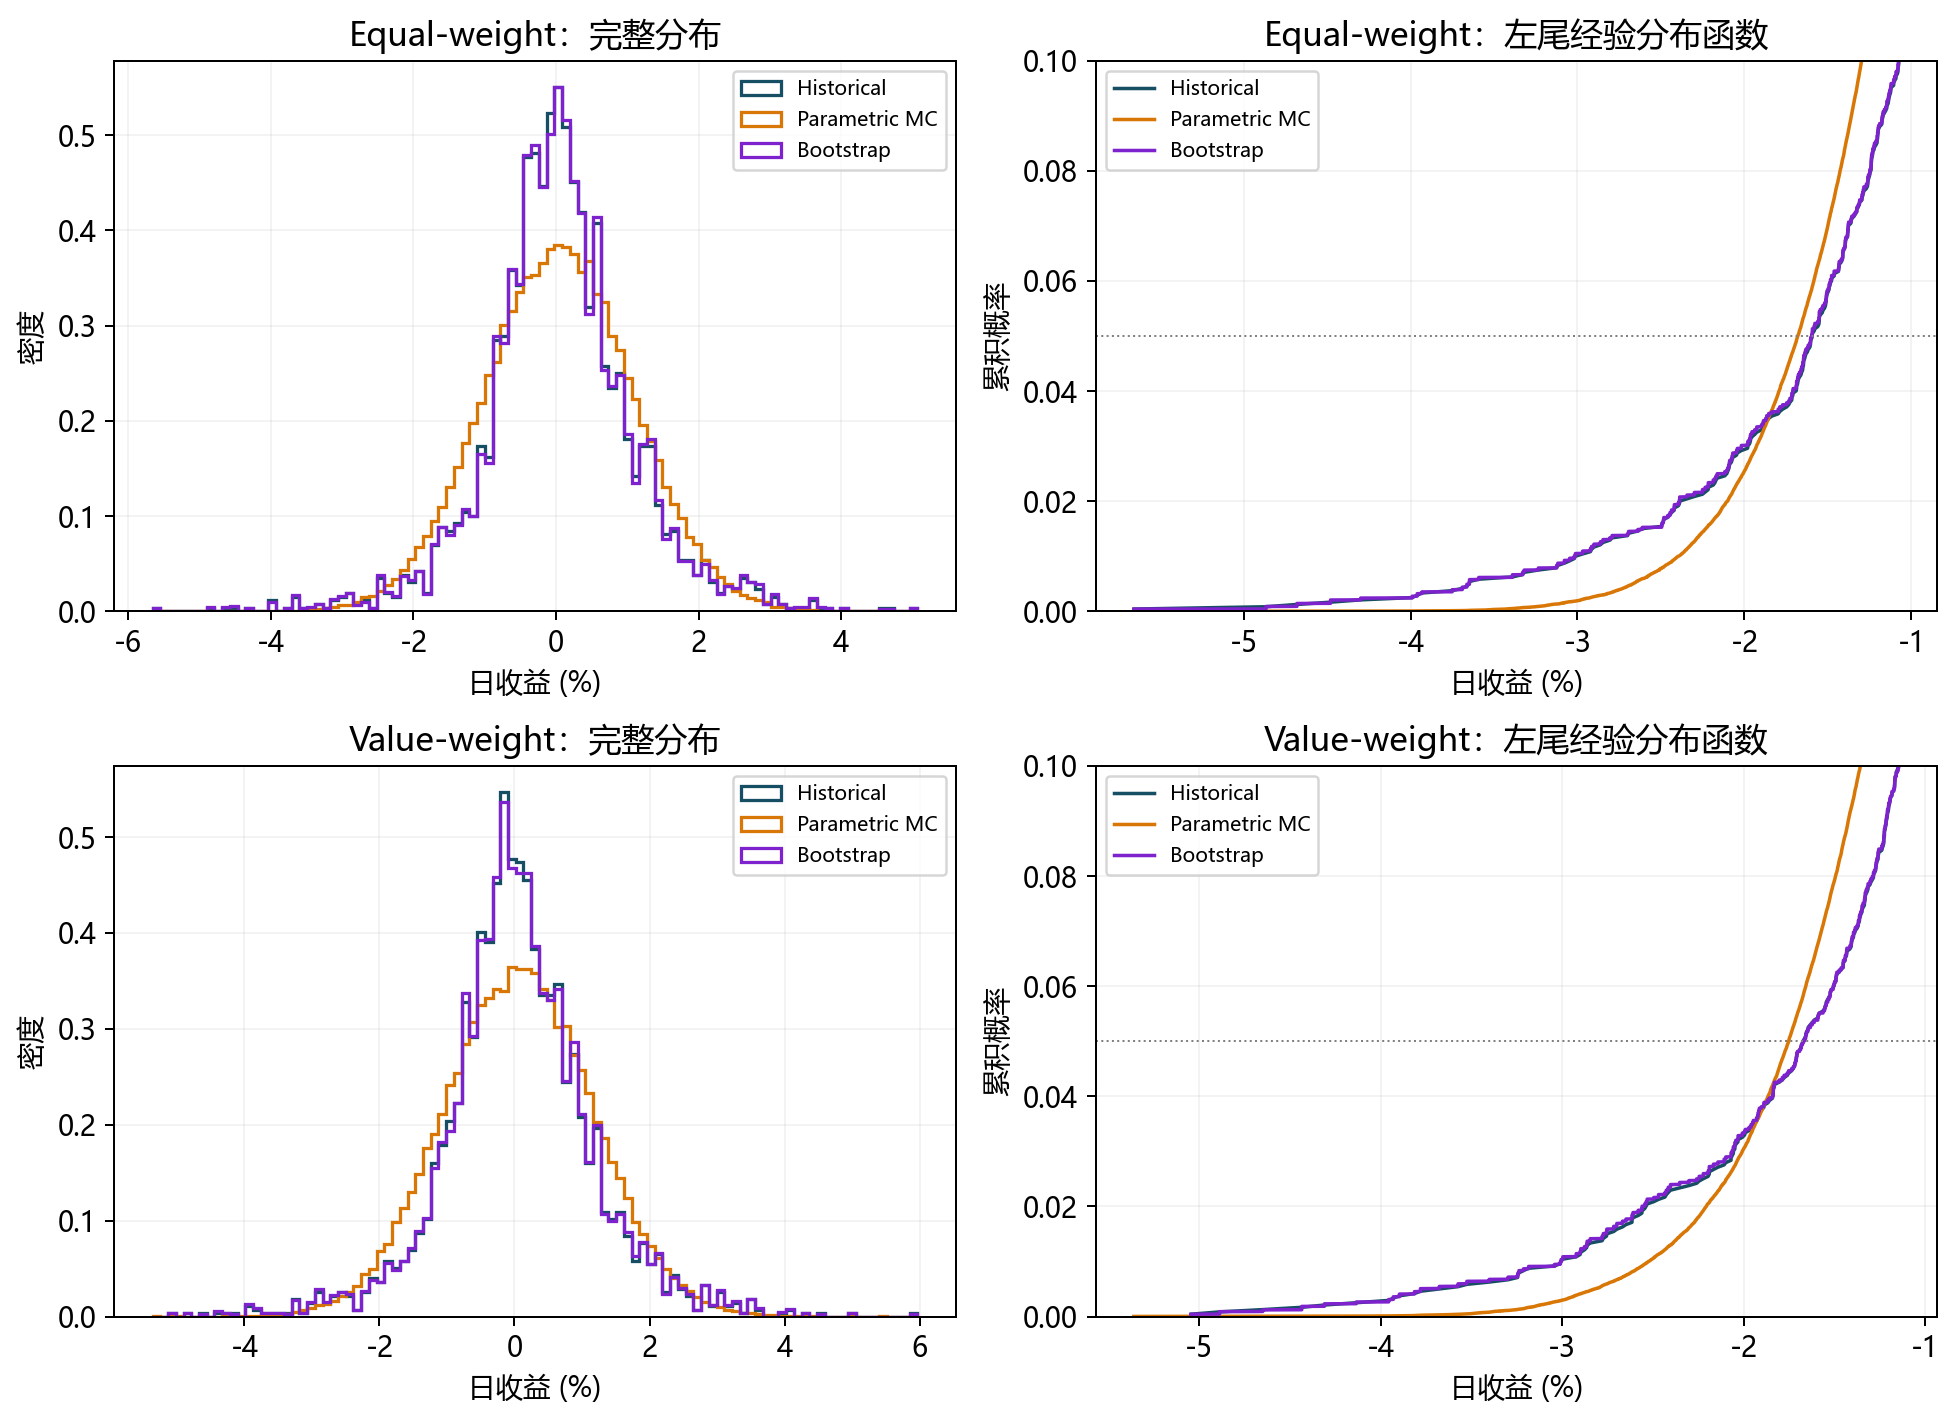

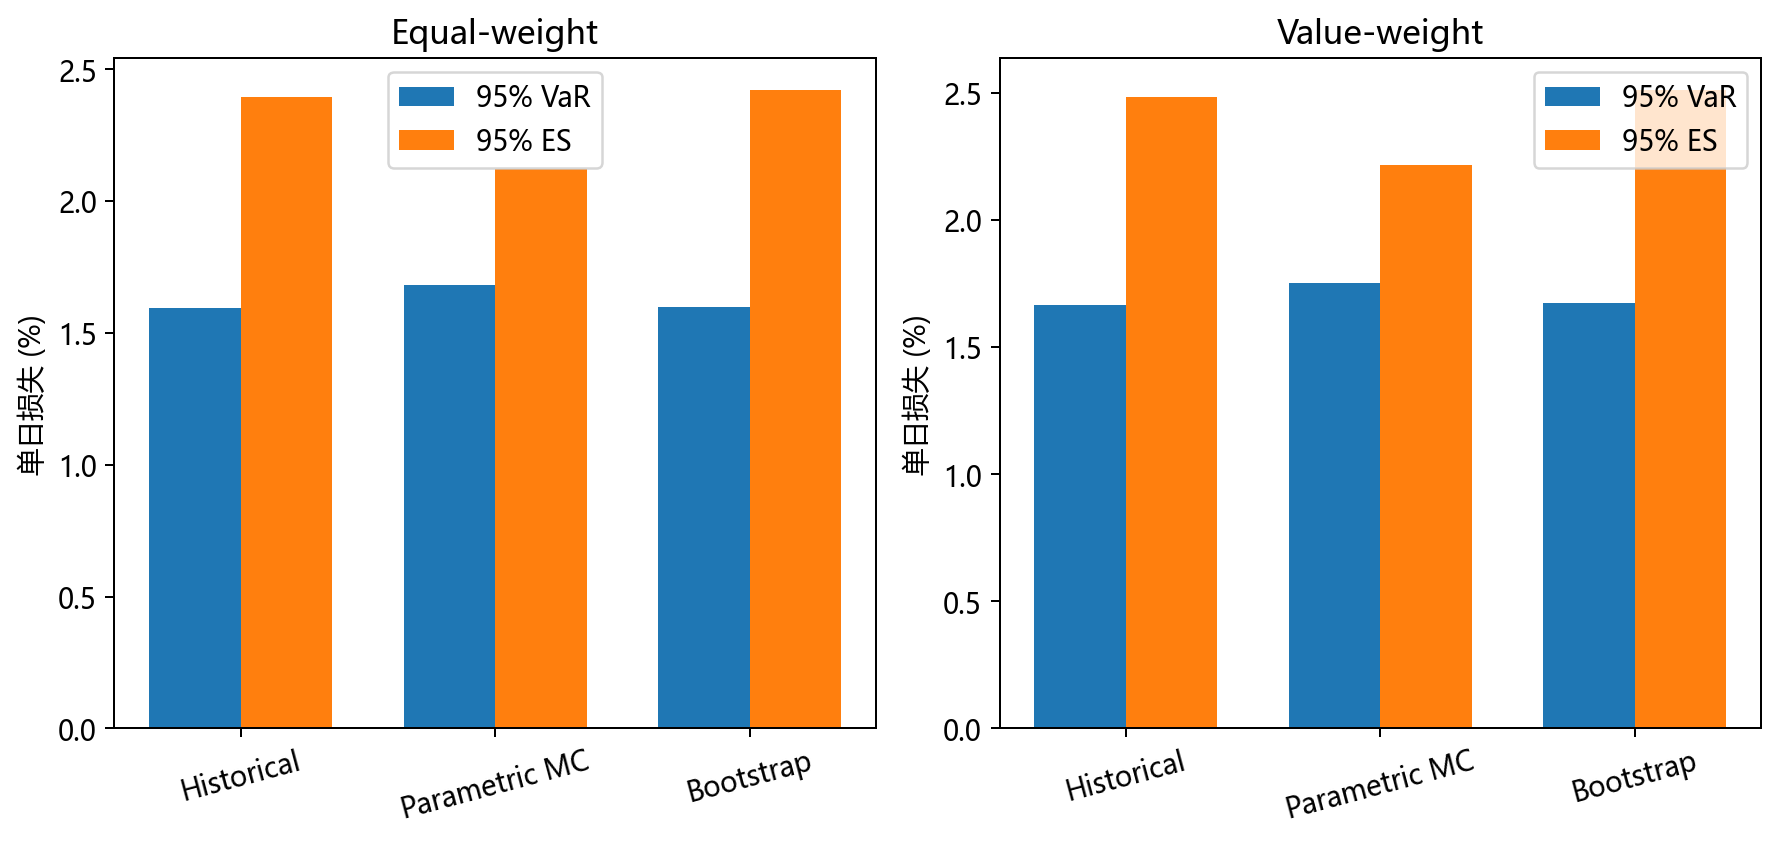

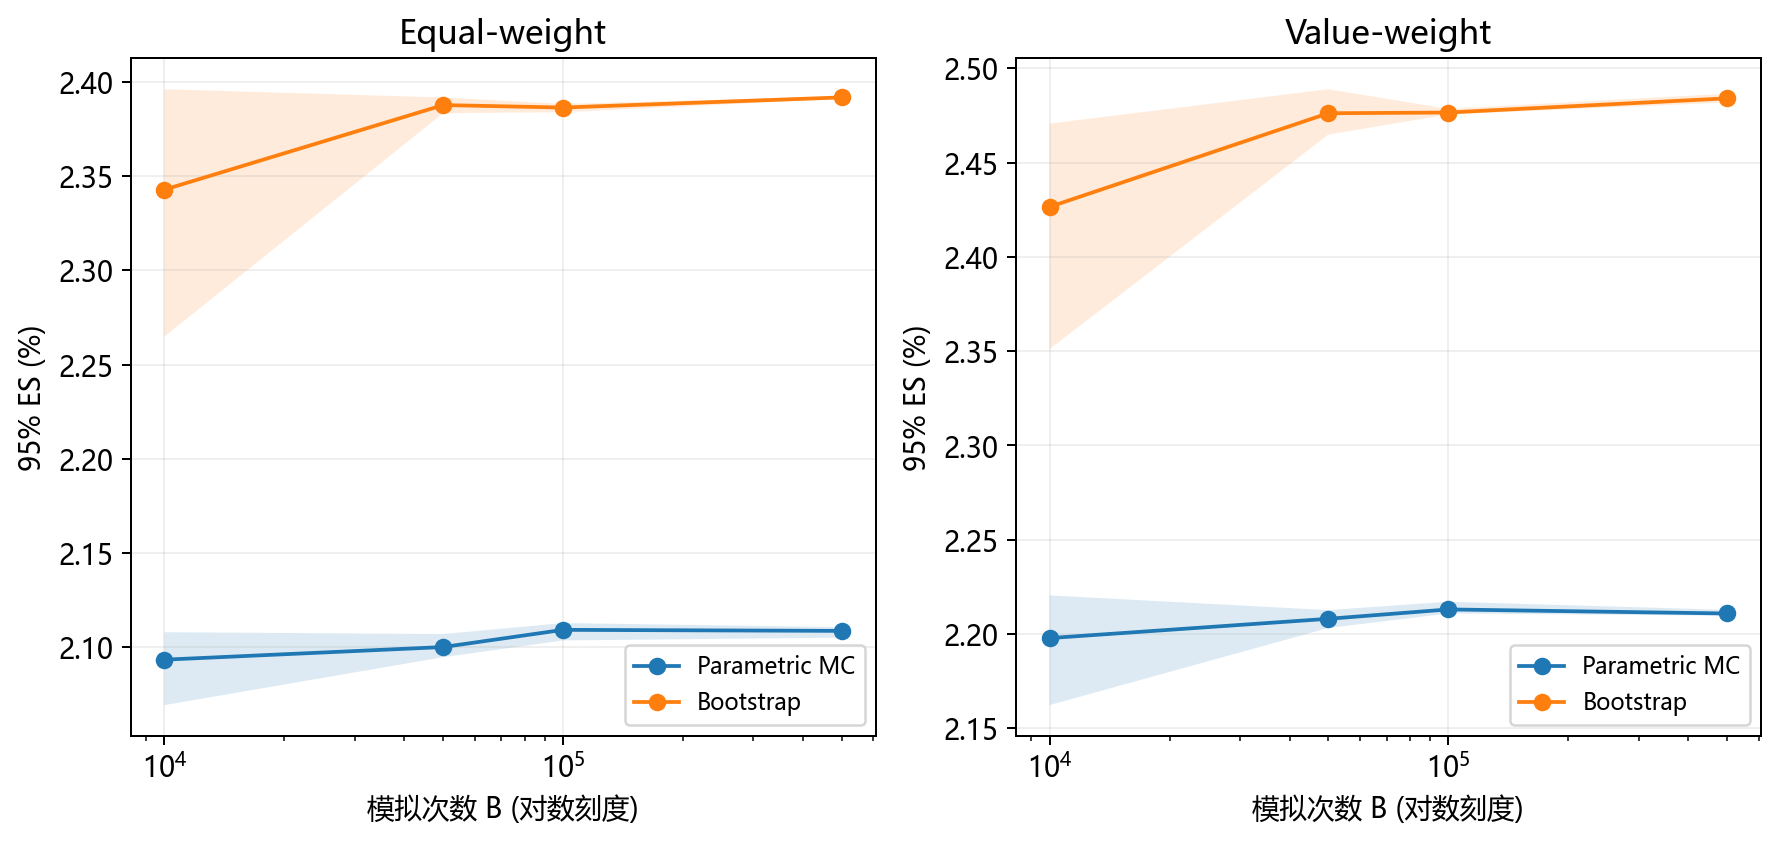

In [8]:
figure_files = a.make_figures(returns, weights, arrays)
for name in figure_files:
    display(Image(filename=str(a.FIG / name)))

## 8. 训练期与评价期

训练期截至 2023-12-31，评价期从 2024-01-01 开始。参数只由训练期收益估计。主案例期末市值权重带有未来信息，因此同时报告训练期末 2023-12-29 权重的敏感性结果；股票池仍为事后选择，不称为严格无前视回测。

均值比较必须使用样本均值的参考分布，不能把多年平均收益与单日收益区间混比。表中均值区间为独立同分布正态且参数固定条件下的 $\hat{\mu}_p\pm1.96\hat{\sigma}_p/\sqrt{n_{test}}$，不包含参数估计误差与序列相关，不能当作稳健显著性检验。另比较日波动、VaR 超越比例与 ES，帮助判断未来样本是否偏离过去模型。

In [9]:
train_test = a.train_test(returns, weights)
display(train_test)
display(pd.read_csv(a.OUT / "train_reference_weights.csv", dtype={"code":str}))

,portfolio,n_train,n_test,train_mean,test_mean,iid_test_mean_lower95,iid_test_mean_upper95,test_mean_z_iid,train_vol,test_vol,sim_VaR95,observed_VaR95,sim_ES95,observed_ES95,VaR_exceedance_rate,mean_inside_iid95
0,Equal-weight,1731,666,0.000416,0.000305,-0.000449,0.001281,-0.250610,0.011392,0.007385,0.018373,0.009895,0.023162,0.015140,0.003003,True
1,Value-weight retrospective,1731,666,0.000573,0.000532,-0.000329,0.001475,-0.090000,0.011878,0.008364,0.019030,0.011653,0.024019,0.017109,0.009009,True
2,Value-weight train-date,1731,666,0.000544,0.000479,-0.000336,0.001425,-0.144624,0.011589,0.008128,0.018557,0.011212,0.023450,0.016769,0.009009,True


,code,reference_date,value_weight
0,600036,2023-12-29,0.325566
1,600900,2023-12-29,0.264998
2,000002,2023-12-29,0.057908
3,000651,2023-12-29,0.084063
4,002594,2023-12-29,0.267465


## 9. 练习与解释边界

把协方差矩阵的非对角项置零，预测等权组合的风险将怎样变化，再计算验证。这个操作用于展示忽略相关性的影响，不能替代本案例主模型。

本案例结论受股票池、停牌筛选、复权口径、样本期和权重基准日影响。正态模型允许小概率收益低于 -100%，没有显式刻画涨跌停、时变波动及危机状态；历史 bootstrap 受已观察样本支持集限制。两者均不自动构成可投资预测。

In [10]:
# 练习核对：相关性通过协方差项进入组合方差。
w = W[:, 0]
variance_joint = w @ Sigma_hat @ w
variance_independent = w @ np.diag(np.diag(Sigma_hat)) @ w
print({"联合模型日波动": np.sqrt(variance_joint), "忽略相关性日波动": np.sqrt(variance_independent)})

{'联合模型日波动': np.float64(0.010432876962820472), '忽略相关性日波动': np.float64(0.007478858206021816)}


## 资料与复现

接口来源：[AKShare 官方股票文档](https://akshare.akfamily.xyz/data/stock/stock.html)，`retrieved_date: 2026-10-01`。本机实测版本及源代码快照见 `logs/`；原始下载参数与日期见 `logs/download-*.json`。最终解释、未决边界和资产映射见 `REPORT.md`、`ASSET_MANIFEST.md`。

独立包运行：`python code/build_notebook.py`。该命令从包内模板重建本 Notebook，使用当前 Python 创建任务局部内核并从头执行。只执行现有 Notebook 也可通过 Jupyter 的 Restart Kernel and Run All Cells 完成。

[返回理论正文](../../lectures/monte-carlo.qmd#sec-mc-portfolio) · [下载 Notebook (ZIP)](../../resources/monte-carlo/downloads/03-portfolio-risk-monte-carlo.zip)

页面展示交接包已保存的执行结果；渲染不执行代码。